# The Rosenbrock function with piazzi

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cai4cai/torch-piazzi/blob/main/notebooks/rosenbrock.ipynb)

The Rosenbrock function is the classic test problem for unconstrained minimisation:

$$f(x, y) = (1 - x)^2 + 100\,(y - x^2)^2 .$$

Its global minimum $f = 0$ sits at $(1, 1)$, at the bottom of a long, curved, nearly flat valley. Finding the valley is easy; following it to the minimum is what makes the problem hard for first-order methods.

This notebook takes its cue from two examples:

- the [Ceres Solver gradient tutorial](https://ceres-solver.readthedocs.io/latest/gradient_tutorial.html), which minimises $f$ from $(-1.2, 1)$ with L-BFGS, and
- the [pytorch-minimize Rosenbrock example](https://github.com/rfeinman/pytorch-minimize/blob/main/examples/rosen_minimize.ipynb), which compares several `scipy.optimize.minimize`-style methods in PyTorch.

We look at the problem in two ways:

1. as a **scalar function**, minimised with `piazzi.minimize` (L-BFGS with an Armijo line search), using only values and gradients;
2. as a **least-squares problem**, $f = r_1^2 + r_2^2$ with residuals $r_1 = 1 - x$ and $r_2 = 10\,(y - x^2)$, solved with Gauss-Newton and Levenberg-Marquardt through `piazzi.least_squares`.

We then compare with SciPy's methods through `piazzi.scipy`, and finish with the $N$-dimensional version.

## Setup

On Colab, the next cell installs `piazzi` from GitHub. Locally, install the notebook dependencies with `uv sync --group notebooks` (see the README).

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q git+https://github.com/cai4cai/torch-piazzi

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize
import torch
from matplotlib.colors import LogNorm

import piazzi
import piazzi.pypose
import piazzi.scipy

torch.set_default_dtype(torch.float64)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["legend.fontsize"] = 12
plt.rcParams["axes.labelsize"] = 14

## The problem

`rosen` is the scalar function and `residuals` its least-squares form. They agree: $f = \|r\|^2$. Note that `piazzi.least_squares`, like SciPy, minimises $\tfrac12\|r\|^2 = f / 2$, so its `result.fun` is half of $f$; the minimiser is the same.

We start from $(-1.2, 1)$, as in the Ceres tutorial and most of the literature.

In [3]:
def rosen(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


def residuals(x):
    return torch.stack([1 - x[0], 10 * (x[1] - x[0] ** 2)])


x0 = torch.tensor([-1.2, 1.0])
x_star = torch.tensor([1.0, 1.0])
print(f"f(x0) = {rosen(x0).item():.4g},  ||r(x0)||^2 = {residuals(x0).square().sum().item():.4g}")

f(x0) = 24.2,  ||r(x0)||^2 = 24.2


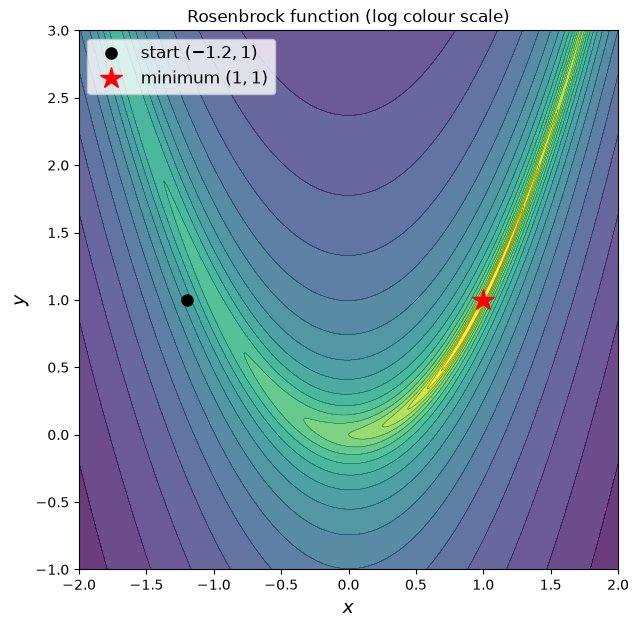

In [4]:
xs = torch.linspace(-2, 2, 401)
ys = torch.linspace(-1, 3, 401)
X, Y = torch.meshgrid(xs, ys, indexing="xy")
Z = rosen(torch.stack([X, Y]))


def plot_landscape(ax):
    levels = np.logspace(-1, 3.5, 19)
    ax.contourf(X, Y, Z + 1e-3, levels=levels, norm=LogNorm(), cmap="viridis_r", alpha=0.8, extend="min")
    ax.contour(X, Y, Z + 1e-3, levels=levels, norm=LogNorm(), colors="k", linewidths=0.3, alpha=0.5)
    ax.plot(*x0, "ko", ms=8, label="start $(-1.2, 1)$")
    ax.plot(*x_star, "r*", ms=16, label="minimum $(1, 1)$")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(7, 7))
plot_landscape(ax)
ax.set_title("Rosenbrock function (log colour scale)")
ax.legend(loc="upper left");

## Recording the iterates and counting evaluations

Every piazzi solver accepts a `callback(info)`, called after each iteration with an `IterationInfo`. A rejected Levenberg-Marquardt step also triggers it (with `info.accepted == False` and `x` unchanged), so we keep only accepted points.

Iterations are a poor measure of cost when the line searches spend extra evaluations on some of them. `IterationInfo` also carries the evaluations so far, by kind: `n_fun_grad` (value and gradient), `n_fun` (value only, or residuals only) and `n_system` (residuals and Jacobian). We turn them into one cost, in units of a value evaluation:

- a value, or the residuals alone, costs 1;
- a value with its gradient costs 2: by the cheap gradient principle, reverse-mode autodiff costs a small constant multiple of the function, typically 2 to 3;
- the residuals with their Jacobian cost $1 + n$ for $n$ parameters: forward-mode autodiff propagates one tangent per parameter, so 3 here.

These weights are rules of thumb; the actual ratios depend on the function and the hardware. Change `cost` to try others.

In [5]:
def cost(counts, n=2):
    """Cost of the evaluations in an IterationInfo or OptimizeResult, in value evaluations."""
    return counts.n_fun + 2 * counts.n_fun_grad + (1 + n) * counts.n_system


class Trace:
    """Callback recording the accepted iterates and the cost so far, starting at x0."""

    def __init__(self):
        self.xs = [x0.clone()]
        self.costs = [0]

    def __call__(self, info):
        if info.accepted:
            self.xs.append(info.x.clone())
            self.costs.append(cost(info))

    @property
    def path(self):
        return torch.stack(self.xs)

    @property
    def values(self):
        return torch.stack([rosen(x) for x in self.xs])

## 1. Scalar minimisation with L-BFGS

`piazzi.minimize` mirrors `scipy.optimize.minimize`; its default method is `lbfgs_armijo`. Each iteration first tries the full L-BFGS step. If that point does not decrease $f$ enough, the line search backtracks along the same direction. Every trial point is evaluated with its autograd graph kept, and the backward pass runs only at the point the line search accepts: an accepted trial costs one value-and-gradient evaluation, and a rejected one costs a forward pass only (counted as value-only).

Ceres reports 36 iterations and 44 value-and-gradient evaluations from the same start, with L-BFGS (memory 20) and a cubic-interpolation Wolfe line search. The Armijo line search here does not enforce the curvature condition, so it needs a few more iterations, but it keeps most iterations at a single evaluation.

In [6]:
trace_lbfgs = Trace()
res_lbfgs = piazzi.minimize(rosen, x0, callback=trace_lbfgs, options={"max_iter": 200})
print(res_lbfgs.message)
print(f"x = {res_lbfgs.x.tolist()},  f = {res_lbfgs.fun.item():.2e}")
r = res_lbfgs
print(f"{r.n_iter} iterations, {r.n_fun_grad} value+gradient and {r.n_fun} value-only evaluations")

step below step_tol
x = [1.0000000008006058, 1.0000000016892432],  f = 1.42e-18
42 iterations, 43 value+gradient and 7 value-only evaluations


### PyTorch's own L-BFGS

`piazzi.minimize` also accepts any `torch.optim` optimiser class as `method`, with its constructor arguments in `options`. We run `torch.optim.LBFGS` twice:

- with its **default** settings, which take fixed steps of length `lr=1` along the L-BFGS direction, with no line search;
- with `line_search_fn="strong_wolfe"`, the cubic-interpolation line search that Ceres also uses.

piazzi runs one L-BFGS iteration per `step`, so `callback` sees every iterate, and applies `max_iter` and torch's `tolerance_grad` and `tolerance_change` to the whole run: the path is exactly that of a single upstream `optimizer.step(closure)` call. It never evaluates the same point twice, which a hand-written loop over `step` would do at the start of every step.

In [7]:
trace_torch, trace_torch_sw = Trace(), Trace()
res_torch = piazzi.minimize(rosen, x0, method=torch.optim.LBFGS, callback=trace_torch, options={"max_iter": 200})
res_torch_sw = piazzi.minimize(
    rosen,
    x0,
    method=torch.optim.LBFGS,
    callback=trace_torch_sw,
    options={"max_iter": 200, "line_search_fn": "strong_wolfe"},
)
for name, res in [("torch L-BFGS (default)", res_torch), ("torch L-BFGS (strong Wolfe)", res_torch_sw)]:
    print(f"{name}: {res.message}")
    print(f"  x = {res.x.tolist()},  f = {res.fun.item():.2e}")
    print(f"  {res.n_iter} iterations, {res.n_fun_grad} value+gradient evaluations")

torch L-BFGS (default): step below tolerance_change
  x = [0.9999987897933501, 0.9999974482598951],  f = 3.19e-12
  62 iterations, 62 value+gradient evaluations
torch L-BFGS (strong Wolfe): step below tolerance_change
  x = [0.9999814210791366, 0.9999619651810989],  f = 4.22e-10
  35 iterations, 43 value+gradient evaluations


With the strong-Wolfe line search, PyTorch's L-BFGS matches Ceres almost exactly: 35 iterations and 43 evaluations, against Ceres's 36 and 44. Its default fixed steps also converge here, but take about 60 iterations, and nothing stops them from going uphill: $f$ goes up on 8 of its iterations, once to about $7 \times 10^7$, as the convergence plot below shows. For deterministic objectives, use the line search.

PyTorch's default `tolerance_change=1e-9` stops it about $10^{-5}$ from the minimiser. Pass a smaller value in `options` for a more accurate solution.

## 2. Least squares: Gauss-Newton and Levenberg-Marquardt

Written as residuals, the problem has more structure to exploit. With the Jacobian

$$J = \begin{pmatrix} -1 & 0 \\ -20x & 10 \end{pmatrix},$$

the gradient of $\tfrac12\|r\|^2$ is $J^\top r$, and $J^\top J$ is a positive semi-definite model of its Hessian. `piazzi.least_squares` builds both with forward-mode autodiff and solves the normal equations:

- `method="gn"`: Gauss-Newton steps with an Armijo backtracking line search;
- `method="lm"` (the default): Levenberg-Marquardt, which blends Gauss-Newton with gradient descent through a damping parameter.

The first Gauss-Newton step from $(-1.2, 1)$ linearises the parabola $y = x^2$, so it jumps straight to $x = 1$ but lands far below the valley, at $y = -3.84$, where $f \approx 2343$. The line search shrinks it, and steps are also capped at `max_step=1` per coordinate by default. We set a tighter `step_tol` than the default `1e-5` to converge to machine precision.

In [8]:
trace_gn, trace_lm = Trace(), Trace()
res_gn = piazzi.least_squares(residuals, x0, method="gn", callback=trace_gn, step_tol=1e-10)
res_lm = piazzi.least_squares(residuals, x0, method="lm", callback=trace_lm, step_tol=1e-10)
for name, res in [("Gauss-Newton", res_gn), ("Levenberg-Marquardt", res_lm)]:
    print(f"{name}: {res.message}")
    print(f"  x = {res.x.tolist()},  f = {rosen(res.x).item():.2e}")
    print(f"  {res.n_iter} iterations, {res.n_system} residual+Jacobian and {res.n_fun} residual-only evaluations")

Gauss-Newton: step below step_tol
  x = [0.9999999999999999, 0.9999999999999997],  f = 1.24e-30
  14 iterations, 23 residual+Jacobian and 14 residual-only evaluations
Levenberg-Marquardt: step below step_tol
  x = [0.999999999999996, 0.9999999999999921],  f = 1.72e-29
  18 iterations, 19 residual+Jacobian and 2 residual-only evaluations


### Paths and convergence

All the methods spend their first iterations working round the bend of the valley. The L-BFGS variants have to learn the curvature from successive gradients, so they creep along the flat valley floor before speeding up near the minimum. Without a line search, torch's default L-BFGS overshoots the valley several times. Gauss-Newton and Levenberg-Marquardt get a curvature model from the Jacobian at every iterate, and converge quadratically once they are close: the residuals vanish at the solution, which is exactly when $J^\top J$ matches the true Hessian.

The convergence plot uses the cost of the evaluations rather than iterations, which charges each method for its line search:

- Gauss-Newton converges in the fewest iterations, but its first steps overshoot the valley and backtrack, so it spends most of its budget before it gets going. Levenberg-Marquardt adapts its damping instead, and is the cheapest overall (59, against 83 for Gauss-Newton).
- PyTorch's strong-Wolfe L-BFGS (86) is slightly cheaper than piazzi's Armijo L-BFGS (93), which takes more iterations. The strong-Wolfe search computes a gradient at every trial point, since its curvature condition needs one, whereas Armijo backtracking computes gradients only at accepted points.

With many parameters the balance shifts towards L-BFGS: its gradient costs a constant multiple of the function, whereas the forward-mode Jacobian costs one pass per parameter.

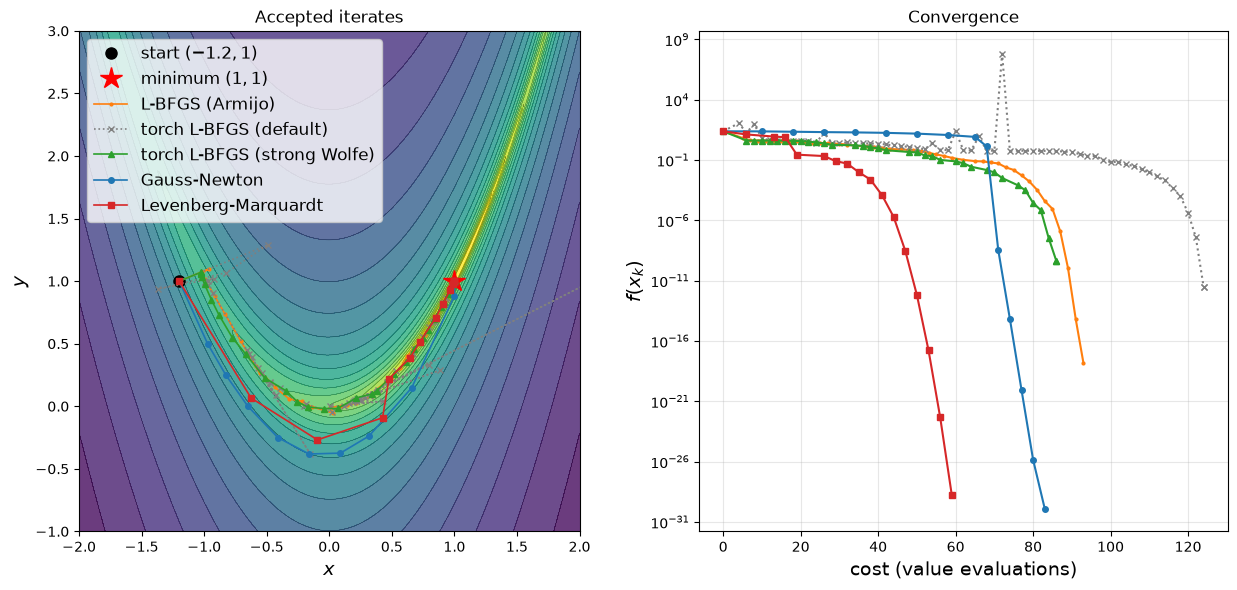

In [9]:
traces = {
    "L-BFGS (Armijo)": trace_lbfgs,
    "torch L-BFGS (default)": trace_torch,
    "torch L-BFGS (strong Wolfe)": trace_torch_sw,
    "Gauss-Newton": trace_gn,
    "Levenberg-Marquardt": trace_lm,
}
styles = {
    "L-BFGS (Armijo)": "C1.-",
    "torch L-BFGS (default)": "C7x:",
    "torch L-BFGS (strong Wolfe)": "C2^-",
    "Gauss-Newton": "C0o-",
    "Levenberg-Marquardt": "C3s-",
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5))
plot_landscape(ax1)
for name, trace in traces.items():
    ax1.plot(*trace.path.T, styles[name], ms=4, lw=1.2, label=name)
ax1.set_xlim(-2, 2)
ax1.set_ylim(-1, 3)
ax1.legend(loc="upper left")
ax1.set_title("Accepted iterates")

for name, trace in traces.items():
    ax2.semilogy(trace.costs, trace.values.clamp(min=1e-32), styles[name], ms=4, label=name)
ax2.set_xlabel("cost (value evaluations)")
ax2.set_ylabel("$f(x_k)$")
ax2.set_title("Convergence")
ax2.grid(True, which="major", alpha=0.3);

## 3. Comparison with SciPy

`piazzi.scipy.minimize` and `piazzi.scipy.least_squares` run SciPy's solvers on the same PyTorch functions, with gradients, Jacobians, Hessians or Hessian-vector products from autograd. `piazzi.pypose.least_squares` does the same for PyPose's Gauss-Newton and Levenberg-Marquardt. This mirrors the method comparison in the pytorch-minimize example.

The evaluation counts are the calls each solver made (the SciPy wrappers count them, rather than relaying SciPy's own `nfev` / `njev` / `nhev`):

- `value+grad`: evaluations of $f$ and its gradient together (one autograd pass);
- `value`: value-only evaluations (line-search trials, the derivative-free Nelder-Mead), or residual-only evaluations for the least-squares solvers;
- `Jac/Hess`: Jacobian evaluations of the least-squares solvers, or Hessian (trust-exact) and Hessian-vector product (Newton-CG, trust-krylov) evaluations.

`cost` weighs them as in the convergence plot, charging a Jacobian, a Hessian or a Hessian-vector product $1 + n = 3$ value evaluations. That is a rough figure for all three here: an exact Hessian costs about $n$ gradient passes, and a Hessian-vector product a double backward pass.

In [10]:
runs = {
    "piazzi L-BFGS (Armijo)": res_lbfgs,
    "torch L-BFGS (default)": res_torch,
    "torch L-BFGS (strong Wolfe)": res_torch_sw,
    "piazzi Gauss-Newton": res_gn,
    "piazzi Levenberg-Marquardt": res_lm,
}
runs["pypose Gauss-Newton"] = piazzi.pypose.least_squares(residuals, x0, method="gn")
runs["pypose LM (trust region)"] = piazzi.pypose.least_squares(residuals, x0)
runs["pypose LM (adaptive)"] = piazzi.pypose.least_squares(residuals, x0, strategy="adaptive")
scipy_runs = {
    "BFGS": {},
    "L-BFGS-B": {},
    "CG": {},
    "Newton-CG": {"hessp": "autodiff"},
    "trust-krylov": {"hessp": "autodiff"},
    "trust-exact": {"hess": "autodiff"},
    "Nelder-Mead": {"jac": None},
}
for method, kwargs in scipy_runs.items():
    runs[f"scipy {method}"] = piazzi.scipy.minimize(rosen, x0, method=method, **kwargs)
for method in ["trf", "lm"]:
    runs[f"scipy least_squares {method}"] = piazzi.scipy.least_squares(residuals, x0, method=method)

print(f"{'solver':32s} {'iter':>5s} {'value+grad':>11s} {'value':>6s} {'Jac/Hess':>11s} {'cost':>5s}", end="")
print(f" {'f(x)':>9s} {'max|x-1|':>9s}")
for name, res in runs.items():
    print(
        f"{name:32s} {res.n_iter:5d} {res.n_fun_grad:11d} {res.n_fun:6d} {res.n_system:11d} {cost(res):5d}"
        f" {rosen(res.x).item():9.1e} {(res.x - 1).abs().max().item():9.1e}"
    )

solver                            iter  value+grad  value    Jac/Hess  cost      f(x)  max|x-1|
piazzi L-BFGS (Armijo)              42          43      7           0    93   1.4e-18   1.7e-09
torch L-BFGS (default)              62          62      0           0   124   3.2e-12   2.6e-06
torch L-BFGS (strong Wolfe)         35          43      0           0    86   4.2e-10   3.8e-05
piazzi Gauss-Newton                 14           0     14          23    83   1.2e-30   3.3e-16
piazzi Levenberg-Marquardt          18           0      2          19    59   1.7e-29   7.9e-15
pypose Gauss-Newton                  1           0      2           1     5   2.4e+01   2.2e+00
pypose LM (trust region)            29           0     42          29   129   0.0e+00   0.0e+00
pypose LM (adaptive)                19           0     36          19    93   0.0e+00   0.0e+00
scipy BFGS                          32          39      0           0    78   2.5e-15   5.4e-08
scipy L-BFGS-B                      36  

All solvers reach $(1, 1)$, each to the accuracy its own stopping rule allows. The quasi-Newton methods with a line search (piazzi's and PyTorch's L-BFGS, SciPy's BFGS and L-BFGS-B) need 30 to 45 iterations. Second-order information helps only when it is used well: trust-exact, with the exact Hessian, takes 25 iterations, while Newton-CG and trust-krylov, which use Hessian-vector products, are no faster than BFGS here. Nelder-Mead, which uses no derivatives at all, needs 159 evaluations. Counting everything, Levenberg-Marquardt is the cheapest (59), followed by SciPy's least-squares solvers and BFGS. The Hessian-based methods pay for their second derivatives: trust-exact costs 130, and Newton-CG, with 142 Hessian-vector products, 636, the most of all.

PyPose's optimisers have no stopping rules or line search, so the wrapper applies piazzi's. PyPose's Gauss-Newton takes a full step with no line search, and from $(-1.2, 1)$ that step raises the cost, so the wrapper rejects it, restores $x_0$ and stops after one iteration without converging (`converged=False`; the table shows $f = 24$). Its Levenberg-Marquardt converges with either damping strategy, in 29 (trust region, PyPose's default) and 19 (adaptive) iterations, but evaluates the residuals at every rejected trial: 129 and 93 against the 59 of piazzi's.

Gauss-Newton and Levenberg-Marquardt need only first derivatives of the *residuals*, yet converge like Newton's method here. That is the point of the least-squares formulation: when the residuals are small at the solution, $J^\top J$ is a good Hessian for free.

## 4. The $N$-dimensional Rosenbrock function

The usual generalisation, used by `scipy.optimize.rosen`, chains the 2-D function over neighbouring coordinates:

$$f(x) = \sum_{i=1}^{N-1} \left[ 100\,(x_{i+1} - x_i^2)^2 + (1 - x_i)^2 \right],$$

with $2(N - 1)$ residuals $10\,(x_{i+1} - x_i^2)$ and $1 - x_i$. The global minimum is still at $x = (1, \dots, 1)$, but for $N \ge 4$ there is also a local minimum near $(-1, 1, \dots, 1)$. We start from $(-1.2, 1, -1.2, 1, \dots)$ with $N = 10$, and check our definition against SciPy's.

In [11]:
def rosen_nd(x):
    return (100 * (x[1:] - x[:-1] ** 2) ** 2 + (1 - x[:-1]) ** 2).sum()


def residuals_nd(x):
    return torch.cat([10 * (x[1:] - x[:-1] ** 2), 1 - x[:-1]])


N = 10
x0_nd = torch.tensor([-1.2, 1.0]).repeat(N // 2)
assert np.isclose(rosen_nd(x0_nd).item(), scipy.optimize.rosen(x0_nd.numpy()))
assert torch.isclose(residuals_nd(x0_nd).square().sum(), rosen_nd(x0_nd))

runs_nd = {
    "piazzi L-BFGS (Armijo)": piazzi.minimize(rosen_nd, x0_nd, options={"max_iter": 500}),
    "torch L-BFGS (strong Wolfe)": piazzi.minimize(
        rosen_nd, x0_nd, method=torch.optim.LBFGS, options={"max_iter": 500, "line_search_fn": "strong_wolfe"}
    ),
    "piazzi Gauss-Newton": piazzi.least_squares(residuals_nd, x0_nd, method="gn", step_tol=1e-10, max_iter=500),
    "piazzi Levenberg-Marquardt": piazzi.least_squares(residuals_nd, x0_nd, step_tol=1e-10, max_iter=500),
    "scipy BFGS": piazzi.scipy.minimize(rosen_nd, x0_nd, method="BFGS"),
    "scipy L-BFGS-B": piazzi.scipy.minimize(rosen_nd, x0_nd, method="L-BFGS-B"),
    "scipy trust-exact": piazzi.scipy.minimize(rosen_nd, x0_nd, method="trust-exact", hess="autodiff"),
    "scipy least_squares trf": piazzi.scipy.least_squares(residuals_nd, x0_nd),
}
print(f"{'solver':28s} {'iter':>5s} {'value+grad':>11s} {'value':>6s} {'Jac/Hess':>11s} {'f(x)':>9s}  x[:3]")
for name, res in runs_nd.items():
    print(
        f"{name:28s} {res.n_iter:5d} {res.n_fun_grad:11d} {res.n_fun:6d} {res.n_system:11d}"
        f" {rosen_nd(res.x).item():9.1e}  {np.round(res.x[:3].numpy(), 4)}"
    )

solver                        iter  value+grad  value    Jac/Hess      f(x)  x[:3]
piazzi L-BFGS (Armijo)          82          83     14           0   1.1e-11  [1. 1. 1.]
torch L-BFGS (strong Wolfe)     69          85      0           0   1.4e-11  [1. 1. 1.]
piazzi Gauss-Newton             21           0     10          32   5.3e-30  [1. 1. 1.]
piazzi Levenberg-Marquardt      27           0      2          27   2.5e-30  [1. 1. 1.]
scipy BFGS                      73          83      0           0   4.0e+00  [-0.9933  0.9966  0.9982]
scipy L-BFGS-B                  71          88      0           0   1.0e-11  [1. 1. 1.]
scipy trust-exact               29          30      0          30   4.0e+00  [-0.9933  0.9966  0.9982]
scipy least_squares trf         22           0     24          22   1.5e-28  [1. 1. 1.]


SciPy's BFGS and trust-exact both settle in the local minimum near $(-1, 1, \dots, 1)$, with $f \approx 3.99$, and report success: it is a genuine stationary point. Which basin a solver ends up in depends on its first few steps, not on how well it converges. The other solvers find the global minimum.

The gap between the least-squares solvers and L-BFGS widens with $N$. The Jacobian costs one forward-mode pass per parameter, which is cheap for the small problems piazzi targets.

## 5. Single precision on a GPU

The solvers run wherever `x0` lives, in its dtype. Here we use a CUDA GPU if there is one (on Colab, choose a GPU runtime), otherwise Apple's MPS backend, otherwise the CPU. MPS has no float64, so this section works in float32.

piazzi solves the small normal equations in float64 on the CPU by default (`solve_dtype`, `solve_device`), so only the objective runs in float32 on the device. All the methods still reach the minimum. With two parameters a GPU is of course slower than the CPU: this only shows that the same code runs there unchanged.

In [12]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"device: {device}")

x0_32 = x0.float().to(device)  # cast on the CPU first: MPS cannot hold float64
runs32 = {
    "L-BFGS (Armijo)": piazzi.minimize(rosen, x0_32),
    "torch L-BFGS (strong Wolfe)": piazzi.minimize(
        rosen, x0_32, method=torch.optim.LBFGS, options={"line_search_fn": "strong_wolfe"}
    ),
    "Gauss-Newton": piazzi.least_squares(residuals, x0_32, method="gn"),
    "Levenberg-Marquardt": piazzi.least_squares(residuals, x0_32),
}
for name, res in runs32.items():
    x = res.x.cpu()
    print(f"{name:28s} {res.x.device.type:4s} {res.x.dtype}  x = [{x[0]:.6f}, {x[1]:.6f}]  ({res.n_iter} iterations)")

device: mps


L-BFGS (Armijo)              mps  torch.float32  x = [1.000000, 1.000000]  (42 iterations)
torch L-BFGS (strong Wolfe)  mps  torch.float32  x = [0.999985, 0.999970]  (35 iterations)
Gauss-Newton                 mps  torch.float32  x = [1.000000, 1.000000]  (12 iterations)
Levenberg-Marquardt          mps  torch.float32  x = [1.000000, 1.000000]  (16 iterations)


## Summary

- As a scalar function, the Rosenbrock function is a hard test for quasi-Newton methods: `piazzi.minimize` (L-BFGS with an Armijo line search) needs about 40 iterations, a few more than Ceres (36) and SciPy's BFGS (32). PyTorch's `torch.optim.LBFGS` with a strong-Wolfe line search, run through `piazzi.minimize`, matches Ceres.
- Written as residuals, the same problem is easy for Gauss-Newton and Levenberg-Marquardt (`piazzi.least_squares`), which use the Jacobian to model the curvature and converge to machine precision in under 20 iterations.
- `piazzi.pypose` runs PyPose's Gauss-Newton and Levenberg-Marquardt through the same interface; the wrapper adds the stopping rules and evaluation counts PyPose lacks.
- `piazzi.scipy` runs SciPy's solvers on the same PyTorch functions, with derivatives from autograd, so you can compare backends without rewriting the problem.